# RIPE with a lightweight backbone: mid-term code

DLCV course project, IIIT Sri City. Vanya Awasthi, Sai Greeshma Venkatanagari.

Baseline: RIPE (Künzel et al., ICCV 2025).
Everything was run on Google Colab with a Tesla T4. The outputs shown are from that run.

| Section | What it does |
|---|---|
| 0 | Setup (RIPE code, Drive, pretrained weights) |
| 1 | Qualitative check of pretrained RIPE on the example pair |
| 2 | HPatches homography reproduction (Glue Factory, `ripe+NN`) |
| 3 | MegaDepth-1500 relative pose reproduction (needs a PoseLib fix) |
| 4 | Our ResNet-18 backbone for RIPE |
| 5 | Computational cost: VGG-19 vs ResNet-18 |

All result numbers in this notebook appear only in cell outputs
from the Colab run; the markdown quotes only the values reported in the official RIPE README.

## 0. Setup

In [ ]:
!git clone https://github.com/fraunhoferhhi/RIPE
%cd RIPE
!pip install -q kornia

Resolving deltas: 100% (53/53), done.
/content/RIPE


In [ ]:
# results are copied to Drive so they survive the Colab session
from google.colab import drive
import os

drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/ripe', exist_ok=True)

Mounted at /content/drive


Drive Folder: https://drive.google.com/drive/folders/111UnnCkBgTxRUhtU72HPsa46R2ACLpVr?usp=sharing

The automatic weight download in `ripe/model_zoo/vgg_hyper.py` failed with an SSL certificate error,
so the 57 MB weight file is fetched manually to `/tmp/ripe_weights.pth`, the path `vgg_hyper()` checks first.

In [ ]:
!rm -f /tmp/ripe_weights.pth
!wget --no-check-certificate https://cvg.hhi.fraunhofer.de/RIPE/ripe_weights.pth -O /tmp/ripe_weights.pth
!ls -lh /tmp/ripe_weights.pth

--2026-10-25 18:34:18--  https://cvg.hhi.fraunhofer.de/RIPE/ripe_weights.pth
HTTP request sent, awaiting response... 200 OK
Length: 59480614 (57M)
Saving to: ‘/tmp/ripe_weights.pth’

/tmp/ripe_weights.p 100%[===================>]  56.72M  18.3MB/s    in 3.6s    

2026-10-25 18:34:22 (16.0 MB/s) - ‘/tmp/ripe_weights.pth’ saved [59480614/59480614]

-rw-r--r-- 1 root root 57M Jun 26  2025 /tmp/ripe_weights.pth


## 1. Qualitative check on the example pair

Same steps as the repository's `demo.py`: up to 2048 keypoints per image, mutual nearest-neighbour
matching, fundamental-matrix RANSAC (Kornia, 1 px). RANSAC is run on CPU because Kornia's linear
algebra kernel failed on the T4 with the default Colab PyTorch build ("no kernel image is available").

Using existing weights from /tmp/ripe_weights.pth
keypoints: 2048 2048 | matches: 966 | inliers: 480


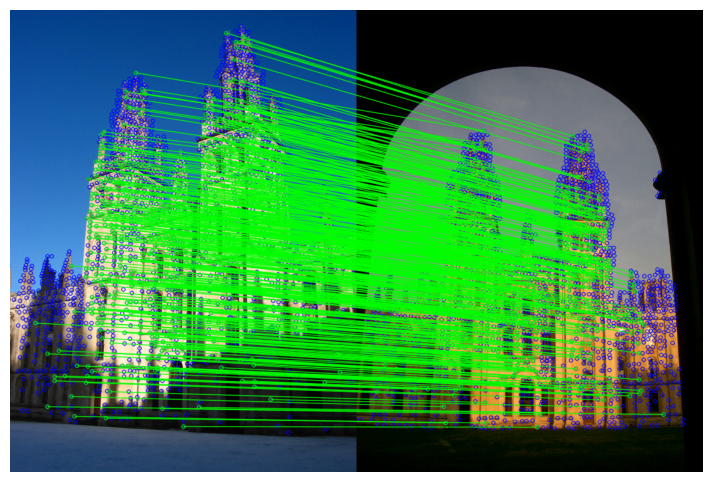

In [ ]:
import cv2, torch, numpy as np, matplotlib.pyplot as plt
import kornia.feature as KF, kornia.geometry as KG
from torchvision.io import decode_image
from ripe import vgg_hyper
from ripe.utils.utils import cv2_matches_from_kornia, resize_image, to_cv_kpts

dev = torch.device("cuda")
model = vgg_hyper().to(dev).eval()

im1 = resize_image(decode_image("assets/all_souls_000013.jpg").float().to(dev) / 255.0)
im2 = resize_image(decode_image("assets/all_souls_000055.jpg").float().to(dev) / 255.0)

k1, d1, s1 = model.detectAndCompute(im1, threshold=0.5, top_k=2048)
k2, d2, s2 = model.detectAndCompute(im2, threshold=0.5, top_k=2048)

dists, idxs = KF.DescriptorMatcher("mnn")(d1, d2)
# RANSAC on CPU, see note above
F, mask = KG.ransac.RANSAC(model_type="fundamental", inl_th=1.0)(k1[idxs[:,0]].cpu(), k2[idxs[:,1]].cpu())
print("keypoints:", len(k1), len(k2), "| matches:", len(idxs), "| inliers:", int(mask.sum()))

out = cv2.drawMatches(
    (im1.cpu().permute(1,2,0).numpy()*255).astype(np.uint8), to_cv_kpts(k1, s1),
    (im2.cpu().permute(1,2,0).numpy()*255).astype(np.uint8), to_cv_kpts(k2, s2),
    cv2_matches_from_kornia(dists, idxs), None, matchColor=(0,255,0),
    matchesMask=mask.int().ravel().tolist(), singlePointColor=(0,0,255))
plt.figure(figsize=(15,6)); plt.imshow(out); plt.axis("off"); plt.savefig("demo_result.png"); plt.show()
!cp demo_result.png /content/drive/MyDrive/ripe/

## 2. HPatches homography estimation

The authors provide their evaluation as a fork of Glue Factory with RIPE as a git submodule.
PoseLib is compiled from source during `uv sync` and needs Eigen, which Colab does not have
(the first `uv sync` failed in CMake for that reason).

In [ ]:
%cd /content
!pip install -q uv
!apt-get install -y -q libeigen3-dev
!git clone https://github.com/JohannesK14/glue-factory
%cd glue-factory
!uv sync
!git submodule update --init --recursive
!ls thirdparty/ripe

/content/glue-factory
Submodule 'thirdparty/ripe' (https://github.com/fraunhoferhhi/RIPE.git) registered for path 'thirdparty/ripe'
Cloning into '/content/glue-factory/thirdparty/ripe'...
Submodule path 'thirdparty/ripe': checked out 'e90c844f68b74c784099b39d625b1fbf8cdb0fd7'
app.py	conda_env.yml  data	LICENSE		   README.md
assets	conf	       demo.py	LICENSE_DALF_DISK  ripe


Protocol of the `ripe+NN` config: 108 HPatches sequences (540 pairs), shorter side 480 px,
top 1024 keypoints, nearest-neighbour matching, PoseLib homography RANSAC at 0.5 px.
Metric: AUC of the corner reprojection error at 1/3/5 px.

In [ ]:
!uv run python -m gluefactory.eval.hpatches --conf ripe+NN
!cp -r /content/glue-factory/outputs/results/hpatches /content/drive/MyDrive/ripe/

Tested ransac setup with following results:
AUC {0.5: [0.3803, 0.5868, 0.6924]}
mAA {0.5: 0.5531666666666667}
best threshold = 0.5
[10/25/2026 19:07:12 gluefactory.eval.eval_pipeline INFO] Loop 2 finished. Results saved to /content/glue-factory/outputs/results/hpatches/ripe+NN.
{'H_error_dlt@1px': 0.0022,
 'H_error_dlt@3px': 0.0056,
 'H_error_dlt@5px': 0.0098,
 'H_error_ransac@1px': 0.3803,
 'H_error_ransac@3px': 0.5868,
 'H_error_ransac@5px': 0.6924,
 'H_error_ransac_mAA': 0.5531666666666667,
 'mH_error_dlt': 133.421,
 'mH_error_ransac': 1.0,
 'mnum_keypoints': 1024.0,
 'mnum_matches': 627.0,
 'mprec@1px': 0.346,
 'mprec@3px': 0.802,
 'mransac_inl': 138.0,
 'mransac_inl%': 0.224}


Values reported in the official RIPE README for this config: 0.3793 / 0.5893 / 0.692 (AUC @1/3/5 px).
Compare with `H_error_ransac@1px/3px/5px` in the output above.

## 3. MegaDepth-1500 relative pose estimation

The first run failed after feature extraction: Glue Factory calls `poselib.estimate_relative_pose`
with the old signature, while the installed PoseLib expects float64 points and an extra
bundle-adjustment options dict. The fix below is the same as `scripts/patch_gluefactory_poselib.py`.

In [ ]:
%cd /content/glue-factory
import sys
from pathlib import Path

root = Path("/content/glue-factory")
p = root / "gluefactory/robust_estimators/relative_pose/poselib.py"
s = p.read_text()

if 'astype("float64")' in s:
    print("already patched")
    raise SystemExit

s = s.replace(
    "pts0.numpy(),\n            pts1.numpy(),",
    'pts0.numpy().astype("float64"),\n            pts1.numpy().astype("float64"),',
)
s = s.replace(
    "**OmegaConf.to_container(self.conf.options),\n            },\n        )",
    "**OmegaConf.to_container(self.conf.options),\n            },\n            {},\n        )",
)
assert 'astype("float64")' in s and "},\n            {},\n        )" in s, "patch did not apply, file layout changed"
p.write_text(s)
print(s[s.find("M, info") : s.find("success =")])

M, info = poselib.estimate_relative_pose(
            pts0.numpy().astype("float64"),
            pts1.numpy().astype("float64"),
            camera0.to_cameradict(),
            camera1.to_cameradict(),
            {
                "max_epipolar_error": self.conf.ransac_th,
                **OmegaConf.to_container(self.conf.options),
            },
            {},
        )
        


Protocol: 1500 pairs, longer side 1600 px, top 2048 keypoints, NN matching, PoseLib RANSAC at 0.5 px.
Metric: AUC of max(rotation error, translation error) at 5/10/20 degrees.

In [ ]:
!uv run python -m gluefactory.eval.megadepth1500 --conf ripe+NN
!cp -r /content/glue-factory/outputs/results/megadepth1500 /content/drive/MyDrive/ripe/

Tested ransac setup with following results:
AUC {0.5: [0.5479, 0.6771, 0.7751]}
mAA {0.5: 0.6667000000000001}
best threshold = 0.5
[10/25/2026 21:24:05 gluefactory.eval.eval_pipeline INFO] Loop 2 finished. Results saved to /content/glue-factory/outputs/results/megadepth1500/ripe+NN.
{'mcovisible': 480.549,
 'mcovisible_percent': 54.306,
 'mepi_prec@1e-3': 0.4359999895095825,
 'mepi_prec@1e-4': 0.10199999809265137,
 'mepi_prec@5e-4': 0.33799999952316284,
 'mgt_match_precision@3px': 0.519,
 'mgt_match_recall@3px': 0.709,
 'mnum_keypoints': 2048.0,
 'mnum_matches': 868.319,
 'mransac_inl': 274.0,
 'mransac_inl%': 0.3269999921321869,
 'mrel_pose_error': 1.5260000228881836,
 'mreproj_prec@1px': 0.268,
 'mreproj_prec@3px': 0.538,
 'mreproj_prec@5px': 0.582,
 'rel_pose_error@10°': 0.6771,
 'rel_pose_error@20°': 0.7751,
 'rel_pose_error@5°': 0.5479,
 'rel_pose_error_mAA': 0.6667000000000001}


Values reported in the official RIPE README for this config: 0.5511 / 0.6834 / 0.7803 (AUC @5/10/20 deg).
Compare with `rel_pose_error@5/10/20` in the output above.

## 4. Proposed ResNet-18 Backbone for RIPE

RIPE's configuration infrastructure references `conf/backbones/resnet.yaml`, but `ripe/models/backbones/resnet.py` is absent from the public release. Directly slotting a standard torchvision `resnet18` into RIPE is not feasible due to four interface mismatches:

1. **Missing Full-Resolution Features:** RIPE samples keypoint detection heatmaps at full input resolution (stride 1). ResNet-18 reduces resolution by $4\times$ in its initial $7\times7$ conv (stride 2) and max-pool (stride 2), providing no stride-1 feature map.
2. **Shifted Strides:** Extracted stages run at strides 4, 8, and 16 (instead of VGG's strides 2, 4, and 8), requiring the coarse-to-fine decoder to bridge irregular spatial scales ($16 \to 8 \to 4 \to 1$).
3. **Hard-coded Decoder Widths:** VGG's decoder expects input channels of `[512, 256, 128, 64]`, which do not match ResNet-18's channel counts `[256, 128, 64, 64]`.
4. **Descriptor Dimensionality:** Concatenating features yields a 512-d hypercolumn instead of VGG's 960-d, altering the input width of the final $1\times1$ projection conv.

### Architectural Solution

* **Parallel Full-Resolution Stem:** We add two $3\times3$ convolutions (32 and 64 channels, stride 1) with BatchNorm and ReLU. Crucially, the stem runs **in parallel** with ResNet's standard input block rather than in front of it, preserving the input distribution expected by the pretrained ImageNet weights.
* **Truncated Backbone:** `layer4` (stride 32, 512 channels) is omitted by default to retain spatial detail and minimize parameter count.
* **Dynamic Decoder & Projection:** Decoder refinement blocks derive their channel widths directly from the encoder's feature maps, handling non-uniform strides via bilinear interpolation. The $1\times1$ descriptor projection is sized automatically from the hypercolumn output (512 $\to$ 256).

### Backbone Selection Rationale

ResNet-18 was selected over deeper residuals (ResNet-34/50) or mobile networks (MobileNetV3) because:

1. **Controlled comparison:** It preserves $3\times3$ standard convolutions, isolating structural benefits (depth, width, skip connections) without changing operator semantics.
2. **Pretrained initialization:** Readily available ImageNet weights match RIPE's training initialization protocol.
3. **Efficiency:** It delivers large parameter and latency reductions (measured in Section 5), where ResNet-34/50 would yield marginal gains.
4. **Optimization:** Residual shortcuts are hypothesized to stabilize training under noisy, high-variance REINFORCE rewards (to be verified empirically in training).

The file shown below is the cleaned-up version submitted in the zip. It builds exactly the network that
produced the output in Section 5 (same layers, same parameter counts); the clean-up only changed comments
and moved the refiner construction into a function.

In [ ]:
%%writefile /content/RIPE/ripe/models/backbones/resnet.py
# ResNet-18 backbone for RIPE (DLCV course project, IIIT Sri City).
#
# Same constructor arguments and outputs as ripe/models/backbones/vgg.py, so it is selected
# with `backbones=resnet` (conf/backbones/resnet.yaml) and the rest of RIPE (keypoint sampling,
# hypercolumn descriptors, matching, RANSAC, REINFORCE) is unchanged.
#
# Why this is not a direct swap of torchvision's ResNet-18:
#   RIPE's VGG-19 encoder returns 4 feature maps at strides 1, 2, 4, 8 (64/128/256/512 ch).
#   The keypoint heatmap is produced at the resolution of the shallowest map, so it must be
#   stride 1. ResNet-18 downsamples 4x in its first two ops (7x7 stride-2 conv + max-pool),
#   so it has no full-resolution feature map at all. We therefore add a small full-resolution
#   stem and take the deeper levels from the pretrained ResNet stages:
#
#     level 1: stem (2x conv3x3)   stride 1    64 ch   new, randomly initialised
#     level 2: ResNet layer1       stride 4    64 ch   ImageNet-pretrained
#     level 3: ResNet layer2       stride 8   128 ch   ImageNet-pretrained
#     level 4: ResNet layer3       stride 16  256 ch   ImageNet-pretrained
#
#   layer4 (512 ch, stride 32) is dropped by default, analogous to RIPE cutting VGG-19 before
#   its conv5 block. num_layers=5 keeps it (ablation).
#   Hypercolumn: 64+64+128+256 = 512-d (VGG: 960-d), projected to 256-d by RIPE's 1x1 conv.
#
#   The VGG decoder has its channel widths hard-coded (512/256/128/64). Here the refiners are
#   built from the encoder dims, so the same code works for any number of levels / widths.

import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as tvm

from .backbone_base import BackboneBase
from .vgg_utils import ConvRefiner, Decoder


class ResNet18Encoder(nn.Module):
    def __init__(self, pretrained=True, num_input_channels=3, num_layers=4):
        super().__init__()
        assert num_layers in (4, 5), "num_layers must be 4 (stem+layer1-3) or 5 (stem+layer1-4)"
        weights = tvm.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        resnet = tvm.resnet18(weights=weights)

        # full-resolution stem: supplies the stride-1 features the heatmap needs
        self.stem = nn.Sequential(
            nn.Conv2d(num_input_channels, 32, 3, 1, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, 1, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )

        if num_input_channels != 3:
            # pretrained conv1 expects RGB; a different input needs a fresh first conv
            resnet.conv1 = nn.Conv2d(num_input_channels, 64, 7, 2, 3, bias=False)

        # Original ResNet input block, stride 4. It runs on the image in parallel to the stem
        # (not on top of it), so the pretrained layers see the input they were trained on.
        self.resnet_in = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        stages = [resnet.layer1, resnet.layer2, resnet.layer3, resnet.layer4]
        self.stages = nn.ModuleList(stages[: num_layers - 1])

        self.dims = [64, 64, 128, 256, 512][:num_layers]

    def get_dim_layers(self):
        return self.dims

    def forward(self, x, **kwargs):
        feats, sizes = [], []

        f = self.stem(x)  # stride 1
        feats.append(f)
        sizes.append(f.shape[-2:])

        f = self.resnet_in(x)  # stride 4
        for stage in self.stages:
            f = stage(f)
            feats.append(f)
            sizes.append(f.shape[-2:])

        return feats, sizes


def build_conv_refiners(dims, num_output_channels, hidden_blocks):
    """Coarse-to-fine decoder refiners with widths derived from the encoder dims.

    Same structure as VGG._create_conv_refiner, which hard-codes the VGG widths.
    Going deepest -> shallowest, each refiner gets [level features, context from the previous
    refiner] and outputs [num_output_channels logits, context sized for the next level].
    """
    rev = list(reversed(dims))  # deep -> shallow
    refiners = {}
    for i, d in enumerate(rev):
        # the deepest level has no incoming context; every later level gets a context
        # tensor with d channels from the refiner before it
        in_dim = d if i == 0 else 2 * d
        ctx_out = rev[i + 1] if i + 1 < len(rev) else 1
        # Keys only need to be unique and ordered deep -> shallow: Decoder iterates over them
        # in insertion order (VGG uses "8", "4", "2", "1").
        refiners[f"level{len(rev) - i}"] = ConvRefiner(
            in_dim,
            d,
            ctx_out + num_output_channels,
            hidden_blocks=hidden_blocks,
            residual=True,
        )
    return nn.ModuleDict(refiners)


class ResNet(BackboneBase):
    def __init__(
        self,
        nchannels=3,
        pretrained=True,
        use_instance_norm=True,
        mode="dect",
        num_layers=4,
    ):
        super().__init__(nchannels=nchannels, use_instance_norm=use_instance_norm)

        self.nchannels = nchannels
        self.mode = mode

        if self.mode not in ["dect", "desc", "dect+desc"]:
            raise ValueError("mode should be 'dect', 'desc' or 'dect+desc'")

        # encoder is built first because the decoder widths depend on it
        self.encoder = ResNet18Encoder(
            pretrained=pretrained,
            num_input_channels=nchannels,
            num_layers=num_layers,
        )

        NUM_OUTPUT_CHANNELS, hidden_blocks = self._get_mode_params(mode)
        conv_refiner = build_conv_refiners(self.encoder.get_dim_layers(), NUM_OUTPUT_CHANNELS, hidden_blocks)
        self.decoder = Decoder(conv_refiner, num_prototypes=NUM_OUTPUT_CHANNELS)

    def _get_mode_params(self, mode):
        # same output channels / refiner depth as the VGG backbone
        if mode == "dect":
            return 1, 8
        elif mode == "desc":
            return 256, 5
        elif mode == "dect+desc":
            return 256 + 1, 8

    def get_dim_layers_encoder(self):
        return self.encoder.get_dim_layers()

    def _forward(self, x):
        # Same coarse-to-fine loop as VGG._forward. Upsampling uses the stored feature sizes,
        # so the non-uniform stride jumps here (16 -> 8 -> 4 -> 1) work without changes.
        features, sizes = self.encoder(x)
        output = 0
        context = None
        scales = list(self.decoder.scales)
        for idx, (feature_map, scale) in enumerate(zip(reversed(features), scales)):
            delta_descriptor, context = self.decoder(feature_map, scale=scale, context=context)
            output = output + delta_descriptor
            if idx < len(scales) - 1:
                size = sizes[-(idx + 2)]
                output = F.interpolate(output, size=size, mode="bilinear", align_corners=False)
                context = F.interpolate(context, size=size, mode="bilinear", align_corners=False)

        if self.mode == "dect":
            return {"heatmap": output, "coarse_descs": features}
        elif self.mode == "desc":
            return {"fine_descs": output, "coarse_descs": features}
        elif self.mode == "dect+desc":
            logits = output[:, :1].contiguous()
            descs = output[:, 1:].contiguous()
            return {"heatmap": logits, "fine_descs": descs, "coarse_descs": features}

Writing /content/RIPE/ripe/models/backbones/resnet.py


## 5. Computational cost: VGG-19 vs ResNet-18

Only the architecture matters here, so both models are randomly initialised and nothing is trained.
We time the network forward pass (`model.net(img)`, encoder + decoder) on one 480x640 image, fp32,
no gradients, 5 warm-up + 30 timed runs, and record peak GPU memory. Keypoint sampling and matching
are the same for both backbones and are excluded.

The output below is from the Colab run of the first revision of this script (same measurement code,
it printed only the two default models and the table had no hypercolumn column).

In [ ]:
%%writefile /content/RIPE/compare_backbones.py
# Computational cost of RIPE with different backbones (DLCV course project, IIIT Sri City).
#
# Measures parameter counts (encoder, encoder+decoder, full model incl. 1x1 descriptor conv),
# forward time of the backbone network and peak GPU memory. These depend only on the
# architecture, so all models are randomly initialised and no training is needed.
#
# Timing covers model.net(img), i.e. encoder + decoder producing the heatmap and the coarse
# feature maps. Keypoint sampling and matching come afterwards and are identical for all
# backbones, so they are excluded.
#
# Usage:  python compare_backbones.py  [--size H W] [--runs N] [--cpu]

import argparse
import gc
import time

import torch

from ripe.models.backbones.resnet import ResNet
from ripe.models.backbones.vgg import VGG
from ripe.models.ripe import RIPE
from ripe.models.upsampler.hypercolumn_features import HyperColumnFeatures

torch.set_grad_enabled(False)

VARIANTS = {
    "VGG-19 (original)": lambda: VGG(pretrained=False),
    "ResNet-18 (ours)": lambda: ResNet(pretrained=False),
}


def count(m):
    return sum(p.numel() for p in m.parameters()) / 1e6


def benchmark(name, backbone, H, W, n_warmup, n_runs, dev):
    model = RIPE(net=backbone, upsampler=HyperColumnFeatures()).to(dev).eval()
    img = torch.rand(1, 3, H, W, device=dev)

    row = dict(
        name=name,
        enc=count(model.net.encoder),
        bb=count(model.net),  # encoder + decoder
        total=count(model),  # + descriptor projection
        hyper=sum(model.net.get_dim_layers_encoder()),
    )

    for _ in range(n_warmup):
        model.net(img)
    if dev.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    t0 = time.perf_counter()
    for _ in range(n_runs):
        model.net(img)
    if dev.type == "cuda":
        torch.cuda.synchronize()
    row["ms"] = (time.perf_counter() - t0) / n_runs * 1000
    row["mem"] = torch.cuda.max_memory_allocated() / 1024**2 if dev.type == "cuda" else float("nan")

    # free this model before building the next one, so peak memory is per model
    del model, img
    gc.collect()
    if dev.type == "cuda":
        torch.cuda.empty_cache()
    return row


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--size", type=int, nargs=2, default=[480, 640], metavar=("H", "W"))
    ap.add_argument("--warmup", type=int, default=5)
    ap.add_argument("--runs", type=int, default=30)
    ap.add_argument("--cpu", action="store_true")
    args = ap.parse_args()

    dev = torch.device("cuda" if torch.cuda.is_available() and not args.cpu else "cpu")
    H, W = args.size
    names = list(VARIANTS)

    rows = [benchmark(n, VARIANTS[n](), H, W, args.warmup, args.runs, dev) for n in names]

    print(f"\nDevice: {torch.cuda.get_device_name() if dev.type == 'cuda' else 'CPU'} | input {H}x{W}\n")
    print(f"{'Model':<24}{'Hypercol':>9}{'Encoder M':>11}{'Enc+Dec M':>11}{'Total M':>9}{'ms/img':>9}{'Peak MB':>9}")
    for r in rows:
        print(
            f"{r['name']:<24}{r['hyper']:>9}{r['enc']:>11.2f}{r['bb']:>11.2f}"
            f"{r['total']:>9.2f}{r['ms']:>9.1f}{r['mem']:>9.0f}"
        )

    v = rows[0]
    print()
    for r in rows[1:]:
        print(
            f"{r['name']} vs VGG-19: {v['enc'] / r['enc']:.1f}x fewer encoder params, "
            f"{v['total'] / r['total']:.1f}x fewer total params, {v['ms'] / r['ms']:.1f}x faster"
        )


if __name__ == "__main__":
    main()

Writing /content/RIPE/compare_backbones.py


In [ ]:
%cd /content/RIPE
!python compare_backbones.py
!cp ripe/models/backbones/resnet.py compare_backbones.py /content/drive/MyDrive/ripe/

Device: Tesla T4 | input 480x640

Model                 Encoder M  Enc+Dec M  Total M   ms/img  Peak MB
VGG-19 (original)         10.59      14.56    14.81    207.5      758
ResNet-18 (ours)           2.80       3.89     4.03     77.6      643

ResNet-18 vs VGG-19: 3.8x fewer encoder params, 3.7x fewer total params, 2.7x faster


Peak memory drops much less than parameters because at inference it is dominated by the full-resolution
activations (stem and last decoder stage), which both variants have. The matching quality of the
ResNet-18 variant is not known yet; it has to be trained first (final phase).